Read data and create Train/Test split

In [130]:
import pandas as pd

books = pd.read_csv("../data/clean/books_clean.csv")
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   book_id      175 non-null    int64  
 1   upc          175 non-null    str    
 2   title        175 non-null    str    
 3   category     175 non-null    str    
 4   description  174 non-null    str    
 5   lang         175 non-null    str    
 6   image_path   175 non-null    str    
 7   price        175 non-null    float64
 8   rating       175 non-null    int64  
 9   product_url  175 non-null    str    
dtypes: float64(1), int64(2), str(7)
memory usage: 13.8 KB


In [131]:
from sklearn.model_selection import train_test_split
train_ids, test_ids = train_test_split(books["book_id"], test_size=0.2, random_state=42, stratify=books["category"])
print("Train:", len(train_ids))
print("Test:", len(test_ids))

Train: 140
Test: 35


In [132]:
split_df = pd.DataFrame({
    "book_id": books["book_id"]
})

split_df["split"] = "train"

split_df.loc[split_df["book_id"].isin(test_ids), "split"] = "test"
split_df.to_csv("../data/features/split.csv",index=False)

display(split_df.head())
print(split_df["split"].value_counts())

,book_id,split
0,998,train
1,958,train
2,954,train
3,946,train
4,939,train


split
train    140
test      35
Name: count, dtype: int64


Model Training

In [133]:
features = pd.read_csv("../data/features/features_word_counts.csv")
split = pd.read_csv("../data/features/split.csv")

print(features.shape)
print(split.shape)

(175, 2116)
(175, 2)


In [134]:
df = features.merge(books[["book_id", "category"]], on="book_id", validate="one_to_one").merge(split, on="book_id", validate="one_to_one")

print(df.shape)
display(df[["book_id", "category", "split"]].head())

(175, 2118)


,book_id,category,split
0,998,Fiction,train
1,958,Fiction,train
2,954,Fiction,train
3,946,Fiction,train
4,939,Fiction,train


In [135]:
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

feature_columns = features.columns.drop("book_id")

X_train = train[feature_columns]
X_test = test[feature_columns]

y_train = train["category"]
y_test = test["category"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (140, 2115)
X_test: (35, 2115)
y_train: (140,)
y_test: (35,)


In [136]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

NB = MultinomialNB()
NB.fit(X_train, y_train)

Y_Pred_NB = NB.predict(X_test)

print("Accuracy:", accuracy_score(y_test, Y_Pred_NB))
print(confusion_matrix(y_test, Y_Pred_NB))
print(classification_report(y_test, Y_Pred_NB))

Accuracy: 0.8571428571428571
[[11  2]
 [ 3 19]]
              precision    recall  f1-score   support

     Fiction       0.79      0.85      0.81        13
  Nonfiction       0.90      0.86      0.88        22

    accuracy                           0.86        35
   macro avg       0.85      0.85      0.85        35
weighted avg       0.86      0.86      0.86        35



In [137]:
from sklearn.linear_model import LogisticRegression

LR = LogisticRegression(max_iter=1000)

LR.fit(X_train, y_train)

Y_Pred_LR = LR.predict(X_test)

print("Accuracy:", accuracy_score(y_test, Y_Pred_LR))
print(confusion_matrix(y_test, Y_Pred_LR))
print(classification_report(y_test, Y_Pred_LR))

Accuracy: 0.8
[[ 7  6]
 [ 1 21]]
              precision    recall  f1-score   support

     Fiction       0.88      0.54      0.67        13
  Nonfiction       0.78      0.95      0.86        22

    accuracy                           0.80        35
   macro avg       0.83      0.75      0.76        35
weighted avg       0.81      0.80      0.79        35



In [138]:
tfidf = pd.read_csv("../data/features/features_tfidf.csv")

df_tfidf = tfidf.merge(books[["book_id", "category"]], on="book_id", validate="one_to_one").merge(split, on="book_id", validate="one_to_one")

print(tfidf.shape)
display(tfidf.head())

(175, 2116)


,book_id,000,10,100,11,13,1942,1945,1950s,1955,...,wrote,wry,year,years,yes,york,young,younger,youngest,youth
0,998,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,958,0.0,0.090247,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.054418,0.0,0.0,0.0
2,954,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.08613,0.0,0.0,0.0,0.077598,0.0,0.0,0.0
3,946,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,939,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [139]:
train_tfidf = df_tfidf[df_tfidf["split"] == "train"]
test_tfidf = df_tfidf[df_tfidf["split"] == "test"]

feature_columns_tfidf = tfidf.columns.drop("book_id")

X_train_tfidf = train_tfidf[feature_columns_tfidf]
X_test_tfidf = test_tfidf[feature_columns_tfidf]

y_train_tfidf = train_tfidf["category"]
y_test_tfidf = test_tfidf["category"]

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(140, 2115)
(35, 2115)


In [140]:
LR_tfidf = LogisticRegression(max_iter=1000)

LR_tfidf.fit(X_train_tfidf, y_train_tfidf)

Y_Pred_LR_tfidf = LR_tfidf.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test_tfidf, Y_Pred_LR_tfidf))

print(confusion_matrix(y_test_tfidf, Y_Pred_LR_tfidf))

print(classification_report(y_test_tfidf, Y_Pred_LR_tfidf))

Accuracy: 0.6571428571428571
[[ 1 12]
 [ 0 22]]
              precision    recall  f1-score   support

     Fiction       1.00      0.08      0.14        13
  Nonfiction       0.65      1.00      0.79        22

    accuracy                           0.66        35
   macro avg       0.82      0.54      0.46        35
weighted avg       0.78      0.66      0.55        35



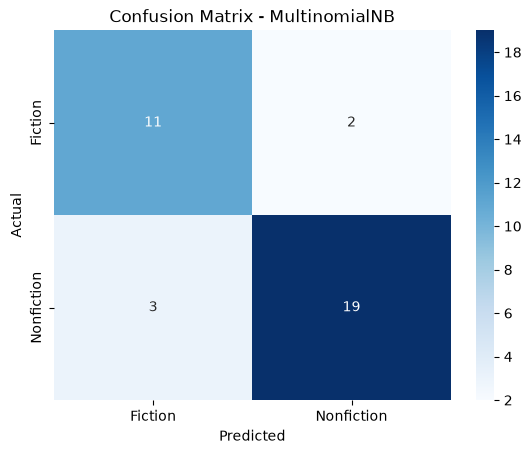

In [141]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = ["Fiction", "Nonfiction"]

cm = confusion_matrix(
    y_test,
    Y_Pred_NB,
    labels=labels
)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - MultinomialNB")
plt.show()

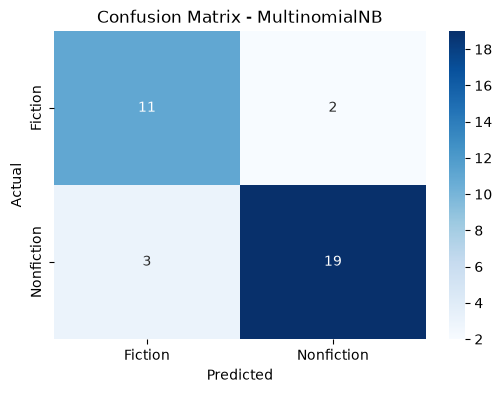

In [142]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - MultinomialNB")

plt.savefig("../results/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [143]:
results = pd.DataFrame({
    "Model": [
        "MultinomialNB + Word Counts",
        "Logistic Regression + Word Counts",
        "Logistic Regression + TF-IDF"
    ],
    "Accuracy": [
        accuracy_score(y_test, Y_Pred_NB),
        accuracy_score(y_test, Y_Pred_LR),
        accuracy_score(y_test_tfidf, Y_Pred_LR_tfidf)
    ]
})

display(results)

results.to_csv("../results/model_comparison.csv", index=False)

,Model,Accuracy
0,MultinomialNB + Word Counts,0.857143
1,Logistic Regression + Word Counts,0.800000
2,Logistic Regression + TF-IDF,0.657143
